# LAB | In God we trust, everyone else bring the data

**Scenario:** you are a marketing analyst. The CMO wants to split a **$500K monthly budget across the marketing channels** and asks you for a **statistically rigorous** recommendation. A false positive means moving money to a channel that isn't really better.

**How to use this notebook:**
- Cells marked **`# TODO`** are yours to complete. Replace every `...` with your code.
- 💡 **Hints** point to the statistics notebook (`03_statistical_analysis.ipynb`), where you saw each idea.
- Run the cells **in order**, top to bottom.

| Part | You will… | Concept from class |
|---|---|---|
| 1 | Find, load and clean a real dataset; compute metrics | A score is an **estimate** |
| 2 | Compare channels (t-test, Fisher) + effect size | p-value, **pick the test by the data**, Cohen's d |
| 3 | Correct for many comparisons | Bonferroni vs Benjamini-Hochberg |
| 4 | Check whether you have enough data | Power and sample size |
| 5 | Turn statistics into a recommendation | Confidence intervals, real vs worth it |

## Part 1 — Dataset discovery & exploration (45–60 min)
### Step 1: Find a dataset (max 30 min)

Search [Kaggle](https://www.kaggle.com/datasets) or [Hugging Face](https://huggingface.co/datasets) for: *marketing channels, advertising campaigns, campaign performance, ad spend, e-commerce conversion, A/B testing*.

Your dataset should have:
- **3+ groups** to compare (channels, campaigns, ad groups…)
- **performance columns**: impressions, clicks, conversions, cost, revenue (not always all of them)
- **repeated rows per group**, ideally one row per **day** or **week** per group (you need this for t-tests and power)

💡 **Hint:** a dataset with **one row per customer** (e.g. "responded yes/no") only works well for Fisher's test (Step 5). Prefer data with many rows per channel.

**✍️ Document your choice here:**
- **Dataset name:** Marketing Campaign Performance Dataset (`marketing_campaign_dataset.csv`)
- **Source + URL:** Kaggle, by manishabhatt22: https://www.kaggle.com/datasets/manishabhatt22/marketing-campaign-performance-dataset
- **Why I chose it:** It has a channel column (`Channel_Used`, 6 channels) and a `Date` column, so I can build **one row per day per channel**, which the t-tests and power analysis need. It has about 200,000 campaign rows with clicks, impressions, conversion rate, acquisition cost and ROI, so I can calculate conversions, cost, revenue, CPA, ROAS and conversion rate. Caveat: the dataset is most likely **synthetic**, so the results are a statistics exercise, not real market evidence.
- **What is one row?** In the raw file, one row = one marketing campaign (company, channel, date, clicks, impressions, conversion rate, cost, ROI). After cleaning, I aggregate to **one row = one channel on one day**.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from pathlib import Path
from IPython.display import Markdown, display

from scipy import stats
from scipy.stats import fisher_exact, false_discovery_control   # false_discovery_control needs SciPy 1.11+

rng = np.random.default_rng(42)          # our "dice": fixed seed so results are repeatable
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)   # all charts / CSV / memo are saved here
sns.set_theme(style="whitegrid")
ALPHA = 0.05

### Step 2: Load, explore, clean

Rename your columns to these **standard names**, so the rest of the notebook works: `date, channel, impressions, clicks, conversions, cost, revenue`. If your dataset lacks a column, leave it out and skip the metrics that need it.

In [ ]:
# TODO: load your dataset
CSV_PATH = "marketing_campaign_dataset.csv"

raw = pd.read_csv(CSV_PATH)

print("Shape:", raw.shape)
print("\nColumns and types:")
print(raw.dtypes)
raw.head()

Shape: (200000, 16)

Columns and types:
Campaign_ID           int64
Company                 str
Campaign_Type           str
Target_Audience         str
Duration                str
Channel_Used            str
Conversion_Rate     float64
Acquisition_Cost        str
ROI                 float64
Location                str
Language                str
Clicks                int64
Impressions           int64
Engagement_Score      int64
Customer_Segment        str
Date                    str
dtype: object


,Campaign_ID,Company,Campaign_Type,Target_Audience,Duration,Channel_Used,Conversion_Rate,Acquisition_Cost,ROI,Location,Language,Clicks,Impressions,Engagement_Score,Customer_Segment,Date
0,1,Innovate Industries,Email,Men 18-24,30 days,Google Ads,0.04,"$16,174.00",6.29,Chicago,Spanish,506,1922,6,Health & Wellness,2021-01-01
1,2,NexGen Systems,Email,Women 35-44,60 days,Google Ads,0.12,"$11,566.00",5.61,New York,German,116,7523,7,Fashionistas,2021-01-02
2,3,Alpha Innovations,Influencer,Men 25-34,30 days,YouTube,0.07,"$10,200.00",7.18,Los Angeles,French,584,7698,1,Outdoor Adventurers,2021-01-03
3,4,DataTech Solutions,Display,All Ages,60 days,YouTube,0.11,"$12,724.00",5.55,Miami,Mandarin,217,1820,7,Health & Wellness,2021-01-04
4,5,NexGen Systems,Email,Men 25-34,15 days,YouTube,0.05,"$16,452.00",6.50,Los Angeles,Mandarin,379,4201,3,Health & Wellness,2021-01-05


In [ ]:
# TODO: clean the data
df = raw.rename(columns={"Date": "date", "Channel_Used": "channel",
                         "Clicks": "clicks", "Impressions": "impressions"}).copy()

# 1. Fix types: date, and cost from text like "$12,345.00" to a number
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["cost"] = pd.to_numeric(df["Acquisition_Cost"].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")

# 2. Derive the missing metrics (documented assumptions)
df["conversions"] = (df["Conversion_Rate"] * df["clicks"]).round()   # conversions = rate x clicks
df["revenue"] = df["cost"] * (1 + df["ROI"])                         # ROI = (revenue - cost) / cost

# 3. Missing values and impossible rows
print("Missing values per column:\n", df[["date", "channel", "clicks", "impressions", "cost", "conversions", "revenue"]].isna().sum(), "\n")
before = len(df)
df = df.dropna(subset=["date", "channel", "cost", "conversions"])
df = df[(df[["clicks", "impressions", "cost", "conversions"]] >= 0).all(axis=1)]
df = df[(df.clicks <= df.impressions) & (df.conversions <= df.clicks)]
print(f"Removed {before - len(df)} impossible / incomplete rows; {len(df)} campaigns left\n")

# 4. Aggregate to ONE ROW PER DAY PER CHANNEL
num_cols = ["impressions", "clicks", "conversions", "cost", "revenue"]
df = df.groupby(["date", "channel"], as_index=False)[num_cols].sum()

# 5. Summary
print("Channels:", df.channel.nunique())
print("Rows (days) per channel:\n", df.channel.value_counts(), "\n")
print("Date range:", df.date.min().date(), "to", df.date.max().date())

# 6. Save the cleaned data
df.to_csv(OUT / "marketing_data.csv", index=False)
print("Saved outputs/marketing_data.csv")

Missing values per column:
 date           0
channel        0
clicks         0
impressions    0
cost           0
conversions    0
revenue        0
dtype: int64 

Removed 0 impossible / incomplete rows; 200000 campaigns left

Channels: 6
Rows (days) per channel:
 channel
Email         365
Facebook      365
Google Ads    365
Instagram     365
Website       365
YouTube       365
Name: count, dtype: int64 

Date range: 2021-01-01 to 2021-12-31
Saved outputs/marketing_data.csv




**✍️ Transformations I made:**
1. **Renamed columns** to the standard names: `Date → date`, `Channel_Used → channel`, `Clicks → clicks`, `Impressions → impressions`.
2. **Converted types:** `date` to datetime; `Acquisition_Cost` from text (e.g. "$12,345.00") to a number, used as **cost**.
3. **Derived missing metrics:** `conversions = Conversion_Rate × clicks` (rounded) and `revenue = cost × (1 + ROI)`, since ROI = (revenue − cost) / cost. These are **assumptions**: the dataset has no direct conversions or revenue columns.
4. **Checked quality:** no missing values; no negative values, clicks > impressions or conversions > clicks. 0 rows removed out of 200,000.
5. **Aggregated** the 200,000 campaign rows to **one row per channel per day**: 6 channels × 365 days (2021-01-01 to 2021-12-31) = 2,190 rows, saved as `outputs/marketing_data.csv`.

**N per channel = 365 days** for the t-tests.

💡 **Think:** how many rows does each channel have? That number is your **N** for the t-tests later.

### Step 3: Key marketing metrics (15–20 min)

| Metric | Formula |
|---|---|
| CTR | clicks / impressions |
| Conversion rate | conversions / clicks |
| CPA | cost / conversions (lower is better) |
| ROAS | revenue / cost (higher is better) |
| Profit · margin | revenue − cost · profit / revenue |

In [4]:
# TODO: totals per channel, then the metrics
agg = df.groupby("channel")[num_cols].sum()

agg["CTR"] = agg.clicks / agg.impressions
agg["conv_rate"] = agg.conversions / agg.clicks
agg["CPA"] = (agg.cost / agg.conversions).where(agg.cost > 0)      # no CPA for zero-cost channels
agg["ROAS"] = (agg.revenue / agg.cost).where(agg.cost > 0)
agg["profit"] = agg.revenue - agg.cost
agg["profit_margin"] = agg.profit / agg.revenue

agg = agg.replace([np.inf, -np.inf], np.nan)
agg.round(3)

,impressions,clicks,conversions,cost,revenue,CTR,conv_rate,CPA,ROAS,profit,profit_margin
channel,,,,,,,,,,,
Email,184801107,18493963,1485425.0,420874104.0,2.524644e+09,0.100,0.08,283.336,5.999,2.103770e+09,0.833
Facebook,180659428,18037947,1446338.0,410595258.0,2.474541e+09,0.100,0.08,283.886,6.027,2.063945e+09,0.834
Google Ads,185006879,18340807,1468717.0,418912314.0,2.516724e+09,0.099,0.08,285.223,6.008,2.097811e+09,0.834
Instagram,183738455,18316654,1462938.0,417124850.0,2.497101e+09,0.100,0.08,285.128,5.986,2.079977e+09,0.833
Website,183806353,18414628,1477660.0,416593500.0,2.504152e+09,0.100,0.08,281.928,6.011,2.087559e+09,0.834
YouTube,183448082,18350407,1463649.0,416778582.0,2.501105e+09,0.100,0.08,284.753,6.001,2.084326e+09,0.833


💡 **Hint: watch out for zero-cost channels** (e.g. SEO, organic). ROAS becomes infinite, and CPA becomes **$0**, which would make the channel look like the best one. Use `.where(agg.cost > 0)` to give them no CPA.

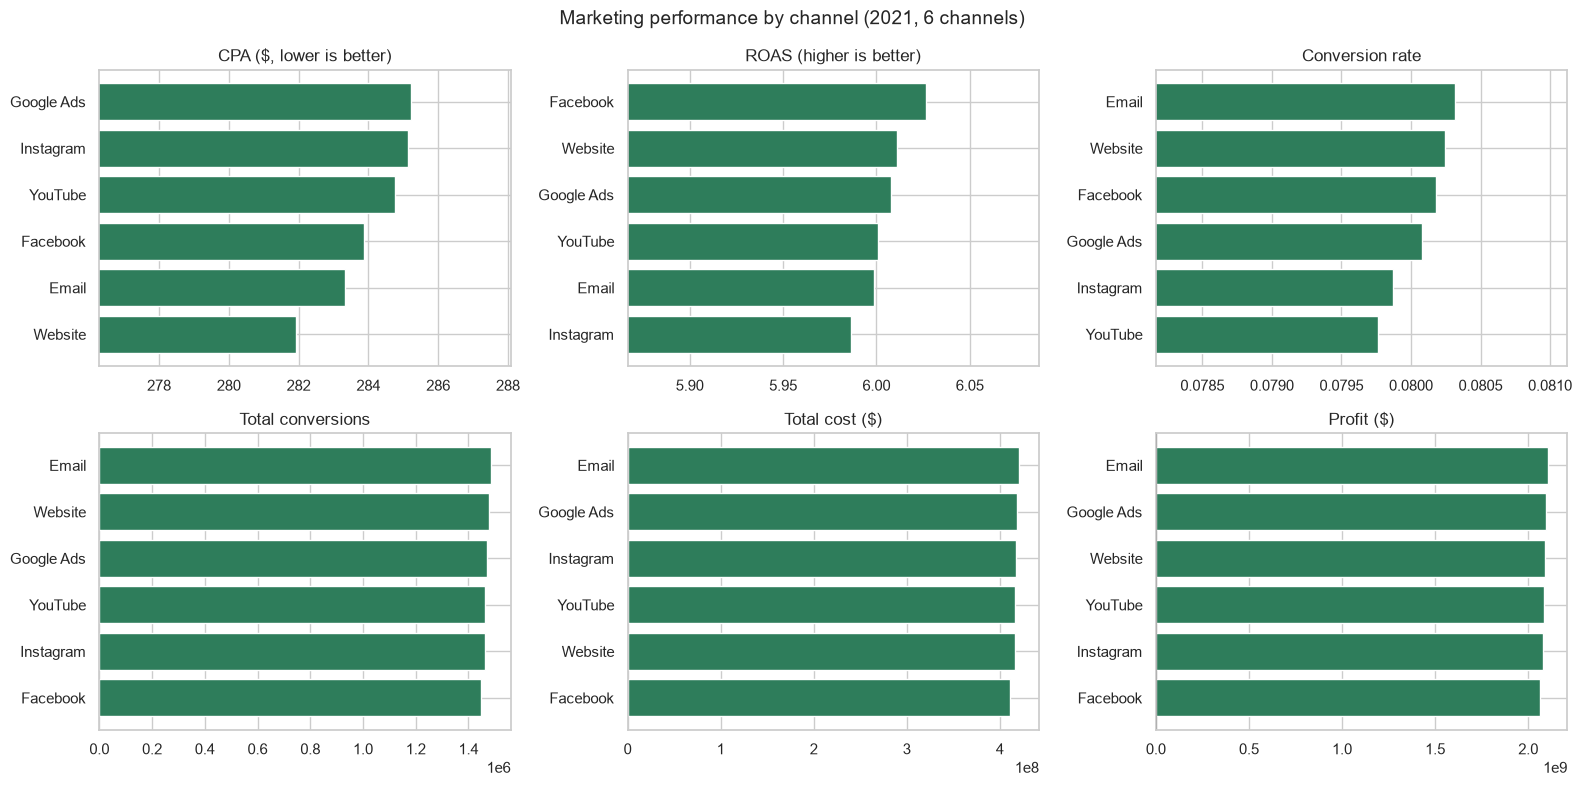

In [5]:
# TODO: 2x3 grid of horizontal bar charts: CPA, ROAS, conversion rate, conversions, cost, profit
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
charts = [
    ("CPA", "CPA ($, lower is better)"),
    ("ROAS", "ROAS (higher is better)"),
    ("conv_rate", "Conversion rate"),
    ("conversions", "Total conversions"),
    ("cost", "Total cost ($)"),
    ("profit", "Profit ($)"),
]
for ax, (col, title) in zip(axes.flat, charts):
    data = agg[col].sort_values()
    ax.barh(data.index, data.values, color="#2E7D5B")
    ax.set_title(title)
    if col == "profit":
        ax.axvline(0, color="black")
    # zoom in so small differences are visible (bars don't start at 0)
    if col in ["CPA", "ROAS", "conv_rate"]:
        ax.set_xlim(data.min() * 0.98, data.max() * 1.01)

plt.suptitle("Marketing performance by channel (2021, 6 channels)", fontsize=14)
plt.tight_layout()
plt.savefig(OUT / "group_metrics_overview.png", dpi=120)
plt.show()

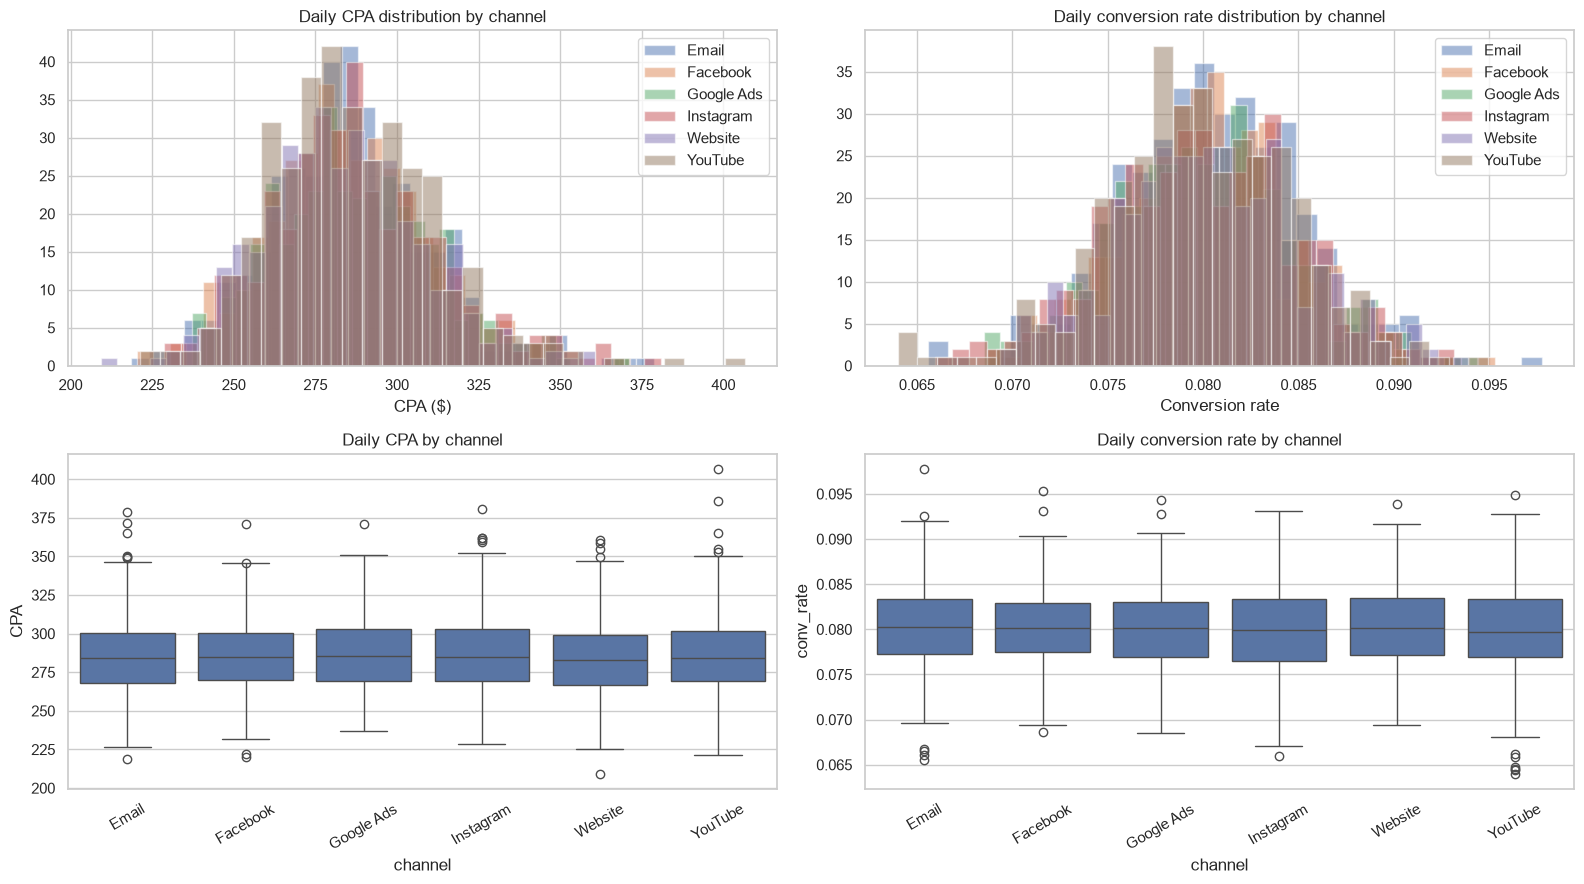

,mean,std,CV
channel,,,
Email,285.070,24.704,0.087
Facebook,285.565,23.313,0.082
Google Ads,286.800,23.990,0.084
Instagram,286.926,26.016,0.091
Website,283.615,24.255,0.086
YouTube,286.442,25.276,0.088


In [6]:
# TODO: per-day (or per-week) metrics -> these give the SPREAD you need for t-tests
# Daily metrics (one value per channel per day)
df["CPA"] = df.cost / df.conversions
df["conv_rate"] = df.conversions / df.clicks
df["ROAS"] = df.revenue / df.cost
df = df.replace([np.inf, -np.inf], np.nan)
paid = df[df.cost > 0]

# Histograms (overlaid) + box plots
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ch in sorted(paid.channel.unique()):
    axes[0, 0].hist(paid.loc[paid.channel == ch, "CPA"], bins=30, alpha=0.5, label=ch)
    axes[0, 1].hist(df.loc[df.channel == ch, "conv_rate"], bins=30, alpha=0.5, label=ch)
axes[0, 0].set_title("Daily CPA distribution by channel"); axes[0, 0].set_xlabel("CPA ($)"); axes[0, 0].legend()
axes[0, 1].set_title("Daily conversion rate distribution by channel"); axes[0, 1].set_xlabel("Conversion rate"); axes[0, 1].legend()

sns.boxplot(data=paid, x="channel", y="CPA", ax=axes[1, 0])
axes[1, 0].set_title("Daily CPA by channel")
sns.boxplot(data=df, x="channel", y="conv_rate", ax=axes[1, 1])
axes[1, 1].set_title("Daily conversion rate by channel")
for ax in axes[1]:
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(OUT / "group_distributions.png", dpi=120)
plt.show()

# Spread per channel: mean, std and CV of daily CPA
variability = paid.groupby("channel")["CPA"].agg(["mean", "std"])
variability["CV"] = variability["std"] / variability["mean"]
variability.round(3)

**✍️ Key insights:**
- **Best channel on each metric (totals):** lowest CPA = **Website** ($281.93); highest ROAS = **Facebook** (6.03); conversion rate and CTR are about 8 % and 10 % for every channel. The highest CPA is Google Ads ($285.22). The total gap between best and worst CPA is only about 1 %.
- **Most variable channel:** **Instagram** (daily CPA std $26.0, CV 9.1 %); most stable: **Facebook** (std $23.3, CV 8.2 %).
- **Outliers:** YouTube has the most extreme days (daily CPA up to about $405, conversion rate down to about 6.5 %); Email has a few very low conversion-rate days. They are rare and do not change the channel averages much.
- **Which channels look close?** **All of them.** The daily CPA distributions overlap almost completely: daily means range from $283.6 to $286.9, a gap of about $3.3, while the day-to-day standard deviation is about $24, **7× larger**. Visually, no channel stands out; any "winner" could be luck.

💡 **Remember (§1–2 of the statistics notebook):** each channel's CPA is an **estimate** from a sample of days, not a fact.

## Part 2 — Pairwise comparisons (60–75 min)
### Step 4: t-tests + Cohen's d

For every **pair** of channels: is the gap in average daily CPA bigger than the day-to-day luck?

💡 **Hints:**
- `from itertools import combinations`: `combinations(groups, 2)` gives every pair once.
- Use **Welch's t-test**: `stats.ttest_ind(b, a, equal_var=False)`. Why Welch and not the default? Look at the test table in §4b.
- Cohen's d = (mean_b − mean_a) / √((var_a + var_b) / 2). Scale: < 0.2 negligible · < 0.5 small · < 0.8 medium · ≥ 0.8 large.

In [7]:
def cohens_d(a, b):
    """Effect size: difference in means divided by the pooled standard deviation."""
    pooled_std = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return (b.mean() - a.mean()) / pooled_std

def effect_label(d):
    d = abs(d)
    if d < 0.2:
        return "negligible"
    elif d < 0.5:
        return "small"
    elif d < 0.8:
        return "medium"
    return "large"

def pairwise_ttests(data, metric):
    clean = data[["channel", metric]].replace([np.inf, -np.inf], np.nan).dropna()
    clean = clean[clean[metric] > 0]
    rows = []
    for a, b in combinations(sorted(clean.channel.unique()), 2):
        xa = clean.loc[clean.channel == a, metric]
        xb = clean.loc[clean.channel == b, metric]
        t, p = stats.ttest_ind(xb, xa, equal_var=False)      # Welch's t-test
        diff = xb.mean() - xa.mean()
        d = cohens_d(xa, xb)
        rows.append({"group_a": a, "group_b": b, "mean_a": xa.mean(), "mean_b": xb.mean(),
                     "diff": diff, "pct_diff": diff / xa.mean() * 100, "t_stat": t, "p_value": p,
                     "cohens_d": d, "effect": effect_label(d), "significant": p < ALPHA})
    res = pd.DataFrame(rows)
    print(f"{metric}: {len(res)} comparisons, {res.significant.sum()} significant")
    return res

cpa_res = pairwise_ttests(paid, "CPA")
cvr_t_res = pairwise_ttests(df, "conv_rate")
cpa_res.round(4)

CPA: 15 comparisons, 0 significant
conv_rate: 15 comparisons, 0 significant


,group_a,group_b,mean_a,mean_b,diff,pct_diff,t_stat,p_value,cohens_d,effect,significant
0,Email,Facebook,285.0703,285.5653,0.4950,0.1736,0.2784,0.7808,0.0206,negligible,False
1,Email,Google Ads,285.0703,286.7996,1.7293,0.6066,0.9594,0.3377,0.0710,negligible,False
2,Email,Instagram,285.0703,286.9262,1.8559,0.6510,0.9883,0.3233,0.0732,negligible,False
3,Email,Website,285.0703,283.6155,-1.4548,-0.5103,-0.8028,0.4223,-0.0594,negligible,False
4,Email,YouTube,285.0703,286.4417,1.3714,0.4811,0.7413,0.4587,0.0549,negligible,False
5,Facebook,Google Ads,285.5653,286.7996,1.2343,0.4322,0.7049,0.4811,0.0522,negligible,False
6,Facebook,Instagram,285.5653,286.9262,1.3609,0.4766,0.7443,0.4570,0.0551,negligible,False
7,Facebook,Website,285.5653,283.6155,-1.9498,-0.6828,-1.1073,0.2685,-0.0820,negligible,False
8,Facebook,YouTube,285.5653,286.4417,0.8764,0.3069,0.4870,0.6264,0.0360,negligible,False
9,Google Ads,Instagram,286.7996,286.9262,0.1266,0.0441,0.0683,0.9455,0.0051,negligible,False


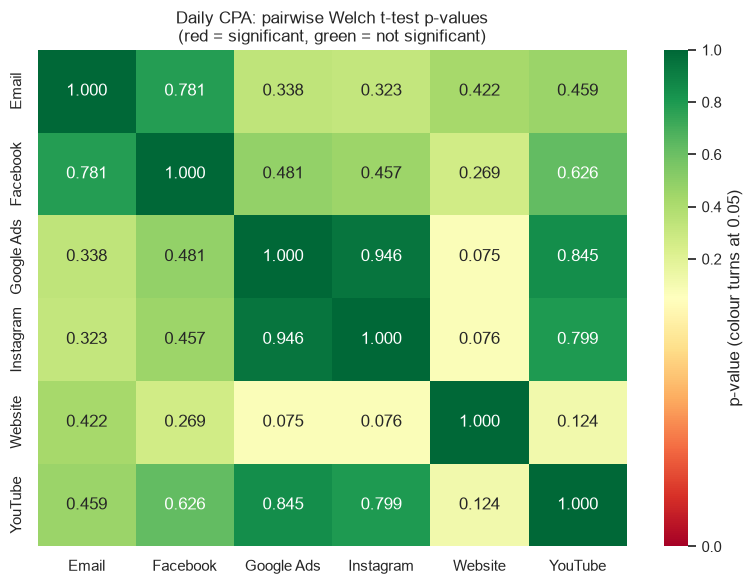

In [10]:
# TODO: heatmap of CPA p-values (channels x channels)
channels = sorted(paid.channel.unique())
pmat = pd.DataFrame(1.0, index=channels, columns=channels)    # diagonal = channel vs itself
for _, r in cpa_res.iterrows():
    pmat.loc[r.group_a, r.group_b] = r.p_value
    pmat.loc[r.group_b, r.group_a] = r.p_value

plt.figure(figsize=(8, 6))
from matplotlib.colors import TwoSlopeNorm
sns.heatmap(pmat, annot=True, fmt=".3f", cmap="RdYlGn",
            norm=TwoSlopeNorm(vmin=0, vcenter=ALPHA, vmax=1),
            cbar_kws={"label": "p-value (colour turns at 0.05)"})
plt.title("Daily CPA: pairwise Welch t-test p-values\n(red = significant, green = not significant)")
plt.tight_layout()
plt.savefig(OUT / "metric_comparison_heatmap.png", dpi=120)
plt.show()

**✍️ Which channels differ significantly? Which pairs can't be told apart?**

**None of the 15 channel pairs differ significantly in daily CPA** (Welch t-test, α = 0.05), and none differ in daily conversion rate either. **All pairs can't be told apart.** The closest calls are Website vs Google Ads (Website about $3.18, or 1.1 %, cheaper; p = 0.075) and Website vs Instagram (about $3.31, or 1.2 %, cheaper; p = 0.076). Every Cohen's d is **negligible** (|d| ≤ 0.13), so even if these gaps were real they would be very small. Because a large p-value means "can't tell", not "no difference", the honest conclusion is: **with 365 days of data, we cannot show that any channel has a better CPA than another.**

💡 **Remember (§3):** a big p-value means **"can't tell"**, not "no difference".

### Step 5: Fisher's exact test on conversions (30–35 min)

Each click either converts or doesn't: **right/wrong data**, so Fisher's exact test (§4b).

```
[[conversions_A, non_conversions_A],
 [conversions_B, non_conversions_B]]
```

In [11]:
# TODO: totals per channel
conv = df.groupby("channel")[["conversions", "clicks"]].sum().astype(int)
conv["non_conversions"] = conv.clicks - conv.conversions
conv["conv_rate"] = conv.conversions / conv.clicks
display(conv)

rows = []
for a, b in combinations(sorted(conv.index), 2):
    table = [[conv.loc[a, "conversions"], conv.loc[a, "non_conversions"]],
             [conv.loc[b, "conversions"], conv.loc[b, "non_conversions"]]]
    odds_ratio, p = fisher_exact(table, alternative="two-sided")
    rate_a, rate_b = conv.loc[a, "conv_rate"], conv.loc[b, "conv_rate"]
    rows.append({"group_a": a, "group_b": b,
                 "conv_a": conv.loc[a, "conversions"], "clicks_a": conv.loc[a, "clicks"],
                 "conv_b": conv.loc[b, "conversions"], "clicks_b": conv.loc[b, "clicks"],
                 "rate_a": rate_a, "rate_b": rate_b,
                 "diff_pp": (rate_b - rate_a) * 100,                 # difference in percentage points
                 "pct_diff": (rate_b - rate_a) / rate_a * 100,
                 "odds_ratio": odds_ratio, "p_value": p, "significant": p < ALPHA})
fisher_res = pd.DataFrame(rows)
print(f"Fisher: {len(fisher_res)} comparisons, {fisher_res.significant.sum()} significant")
fisher_res[["group_a", "group_b", "rate_a", "rate_b", "diff_pp", "pct_diff", "p_value", "significant"]].round(5)

,conversions,clicks,non_conversions,conv_rate
channel,,,,
Email,1485425,18493963,17008538,0.080319
Facebook,1446338,18037947,16591609,0.080183
Google Ads,1468717,18340807,16872090,0.080079
Instagram,1462938,18316654,16853716,0.079869
Website,1477660,18414628,16936968,0.080244
YouTube,1463649,18350407,16886758,0.079761


Fisher: 15 comparisons, 9 significant


,group_a,group_b,rate_a,rate_b,diff_pp,pct_diff,p_value,significant
0,Email,Facebook,0.08032,0.08018,-0.01364,-0.16980,0.12940,False
1,Email,Google Ads,0.08032,0.08008,-0.02403,-0.29913,0.00728,True
2,Email,Instagram,0.08032,0.07987,-0.04502,-0.56048,0.00000,True
3,Email,Website,0.08032,0.08024,-0.00756,-0.09417,0.39809,False
4,Email,YouTube,0.08032,0.07976,-0.05583,-0.69514,0.00000,True
5,Facebook,Google Ads,0.08018,0.08008,-0.01039,-0.12955,0.24866,False
6,Facebook,Instagram,0.08018,0.07987,-0.03138,-0.39134,0.00049,True
7,Facebook,Website,0.08018,0.08024,0.00607,0.07576,0.50003,False
8,Facebook,YouTube,0.08018,0.07976,-0.04220,-0.52624,0.00000,True
9,Google Ads,Instagram,0.08008,0.07987,-0.02099,-0.26213,0.01916,True


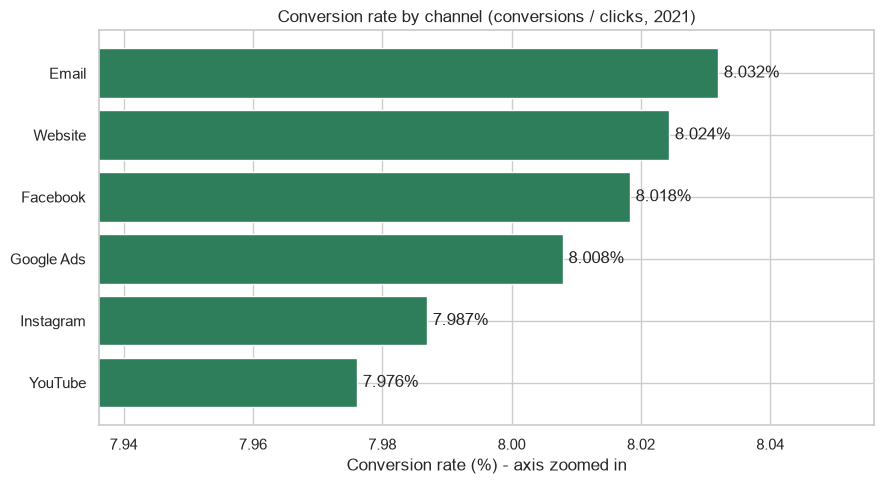

Significant with Fisher: 9 | with t-test: 0
Pairs where the tests disagree: 9


,group_a,group_b,diff_pp,p_value_fisher,significant_fisher,p_value_ttest,significant_ttest
1,Email,Google Ads,-0.02403,0.00728,True,0.53192,False
2,Email,Instagram,-0.04502,0.00000,True,0.25707,False
4,Email,YouTube,-0.05583,0.00000,True,0.15175,False
6,Facebook,Instagram,-0.03138,0.00049,True,0.41199,False
8,Facebook,YouTube,-0.04220,0.00000,True,0.25698,False
9,Google Ads,Instagram,-0.02099,0.01916,True,0.59255,False
11,Google Ads,YouTube,-0.03181,0.00038,True,0.40086,False
12,Instagram,Website,0.03745,0.00003,True,0.35344,False
14,Website,YouTube,-0.04827,0.00000,True,0.21708,False


In [12]:
# TODO: horizontal bar chart of conversion rates, sorted, with % labels (plt.bar_label)
# Bar chart of conversion rates, sorted, with % labels
rates = conv["conv_rate"].sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(rates.index, rates.values * 100, color="#2E7D5B")
ax.bar_label(bars, labels=[f"{v:.3f}%" for v in rates.values * 100], padding=4)
ax.set_xlim(rates.min() * 100 * 0.995, rates.max() * 100 * 1.003)   # zoomed in: differences are tiny
ax.set_xlabel("Conversion rate (%) - axis zoomed in")
ax.set_title("Conversion rate by channel (conversions / clicks, 2021)")
plt.tight_layout()
plt.savefig(OUT / "rate_comparison.png", dpi=120)
plt.show()

# Fisher vs t-test on conversion rate: do they agree?
compare = fisher_res[["group_a", "group_b", "diff_pp", "p_value", "significant"]].merge(
    cvr_t_res[["group_a", "group_b", "p_value", "significant"]],
    on=["group_a", "group_b"], suffixes=("_fisher", "_ttest"))
disagree = compare[compare.significant_fisher != compare.significant_ttest]
print(f"Significant with Fisher: {compare.significant_fisher.sum()} | with t-test: {compare.significant_ttest.sum()}")
print(f"Pairs where the tests disagree: {len(disagree)}")
disagree.round(5)

**✍️ Answer:**
1. **Which channels have significantly different conversion rates?** With Fisher's exact test, **9 of 15 pairs** are significant (α = 0.05). **Email, Website and Facebook** have slightly higher rates (about 8.02–8.03 %) than **Instagram and YouTube** (about 7.98 %), with Google Ads in between (8.01 %). With the t-test on daily conversion rates, **0 of 15 pairs** are significant.
2. **Are the differences large enough to matter?** **No.** All channels convert between **7.98 % and 8.03 %**. The biggest gap (Email vs YouTube) is only **0.056 percentage points** (0.7 % relative), about **1 extra conversion per 1,800 clicks**. That is statistically detectable, but far too small to justify moving budget.
3. **Fisher vs t-test: do they agree? If not, why?** **No, they disagree on 9 pairs.** The reason is **N**. Fisher counts every click as an observation (about **18 million clicks per channel**), so even microscopic differences become "significant". The t-test uses **365 daily rates per channel**, and the day-to-day noise is much bigger than these tiny gaps. Large N makes tiny effects significant, so with huge samples we must judge the **size** of a difference, not just its p-value.

💡 **Hint for 3:** compare the **N** of each test. For Fisher, N = number of clicks. For the t-test, N = number of days. What did §3b show about large N and small gaps?

## Part 3 — Multiple comparisons correction (45–60 min)
### Step 6: Bonferroni and Benjamini-Hochberg

💡 **Hints (§8 of the statistics notebook):**
- Bonferroni: significant if `p < ALPHA / number_of_tests`
- BH: `false_discovery_control(p_values, method="bh")` returns **adjusted** p-values; significant if adjusted < ALPHA

In [13]:
families = {"CPA (t-test)": cpa_res, "Conv. rate (t-test)": cvr_t_res, "Conv. rate (Fisher)": fisher_res}

total_tests = sum(len(r) for r in families.values())
print(f"Total tests: {total_tests}")
print(f"Expected false positives by chance alone at alpha=0.05: {total_tests * ALPHA:.2f}")
print("-> with this many tests, some 'significant' results can appear just by luck.\n")

rows = []
for name, res in families.items():
    m = len(res)
    res["significant_bonferroni"] = res["p_value"] < ALPHA / m
    res["p_value_fdr"] = false_discovery_control(res["p_value"].values, method="bh")
    res["significant_fdr"] = res["p_value_fdr"] < ALPHA
    rows.append({"family": name, "tests": m,
                 "uncorrected": int(res["significant"].sum()),
                 "Bonferroni": int(res["significant_bonferroni"].sum()),
                 "BH-FDR": int(res["significant_fdr"].sum())})
correction_summary = pd.DataFrame(rows).set_index("family")
correction_summary

Total tests: 45
Expected false positives by chance alone at alpha=0.05: 2.25
-> with this many tests, some 'significant' results can appear just by luck.



,tests,uncorrected,Bonferroni,BH-FDR
family,,,,
CPA (t-test),15,0,0,0
Conv. rate (t-test),15,0,0,0
Conv. rate (Fisher),15,9,7,9


CPA (t-test):
  lost after Bonferroni: none
  lost after BH-FDR:     none
Conv. rate (t-test):
  lost after Bonferroni: none
  lost after BH-FDR:     none
Conv. rate (Fisher):
  lost after Bonferroni: ['Email vs Google Ads', 'Google Ads vs Instagram']
  lost after BH-FDR:     none


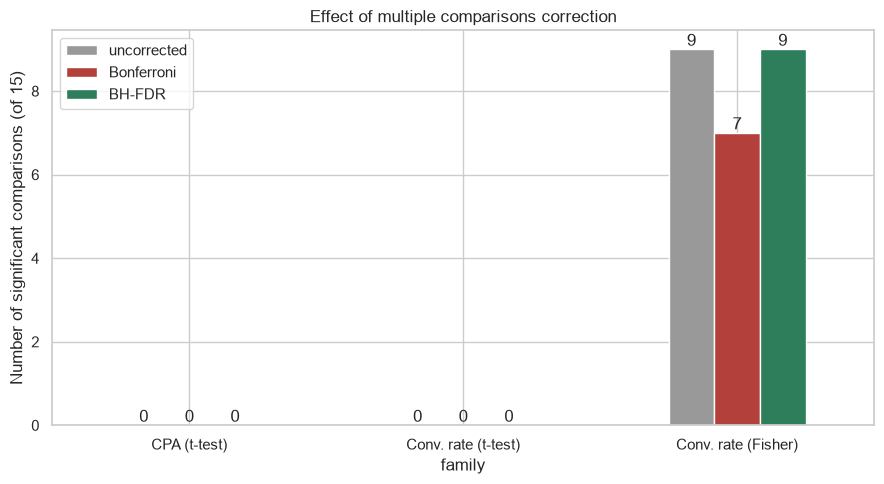

In [14]:
# TODO: which comparisons lose significance after each correction? Print them.
...

# TODO: grouped bar chart: uncorrected vs Bonferroni vs BH per family
...
# Which comparisons lose significance after each correction?
for name, res in families.items():
    lost_bonf = res[res.significant & ~res.significant_bonferroni]
    lost_fdr = res[res.significant & ~res.significant_fdr]
    print(f"{name}:")
    print("  lost after Bonferroni:", [f"{a} vs {b}" for a, b in zip(lost_bonf.group_a, lost_bonf.group_b)] or "none")
    print("  lost after BH-FDR:    ", [f"{a} vs {b}" for a, b in zip(lost_fdr.group_a, lost_fdr.group_b)] or "none")

# Grouped bar chart: uncorrected vs Bonferroni vs BH per family
ax = correction_summary[["uncorrected", "Bonferroni", "BH-FDR"]].plot(
    kind="bar", figsize=(9, 5), color=["#999999", "#B3403A", "#2E7D5B"])
ax.set_ylabel("Number of significant comparisons (of 15)")
ax.set_title("Effect of multiple comparisons correction")
ax.tick_params(axis="x", rotation=0)
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.savefig(OUT / "correction_comparison.png", dpi=120)
plt.show()

**✍️ Answer:**
1. **How many "significant" results disappeared after correction?** We ran **45 tests**, so about **2.25 false positives** are expected by chance alone. **Bonferroni removed 2 of the 9** Fisher results (Email vs Google Ads, p = 0.007; Google Ads vs Instagram, p = 0.019), leaving 7. **BH-FDR removed none** (9 remain). The CPA and conversion-rate t-tests had **0** significant results before correction, so there was nothing to remove.
2. **Which correction fits a budget decision, and why?** We choose by the **cost of a false winner**. Moving part of a $500K monthly budget to a channel that is not really better is expensive, so a false positive costs more than a missed opportunity. That favours the **stricter Bonferroni** correction for the final decision. BH-FDR is better for **exploration** (deciding what to test next), where a few false leads are acceptable.
3. **What does this mean for moving budget?** **No result justifies moving budget.** On **CPA**, the metric that matters most for spend, no channel is significantly better, before or after correction. The only results that survive correction are Fisher conversion-rate differences of **at most 0.056 percentage points**, which are real but far too small to matter. The safe decision is to keep the allocation roughly even and **run controlled tests** before shifting money.

## Part 4 — Power analysis (30–45 min)
### Step 7: Do we have enough data?

**Power** = the chance of catching a difference that is **really** there (§5). Simulate many experiments where you **know** the truth:
- channel A: daily CPA ~ normal(mean = `base_cpa`, std = 15% of `base_cpa`)
- channel B: the same, but mean = `base_cpa × (1 + true_diff_pct)`
- cap low values at 50% of `base_cpa` (`np.maximum(x, 0.5 * base_cpa)`)
- t-test → count how often p < 0.05

💡 **Speed hint:** draw all simulations at once with shape `(n_sim, n_days)` and use `stats.ttest_ind(a, b, axis=1)`. A plain loop also works, but use `n_sim=300` then.

Base CPA: $284.24


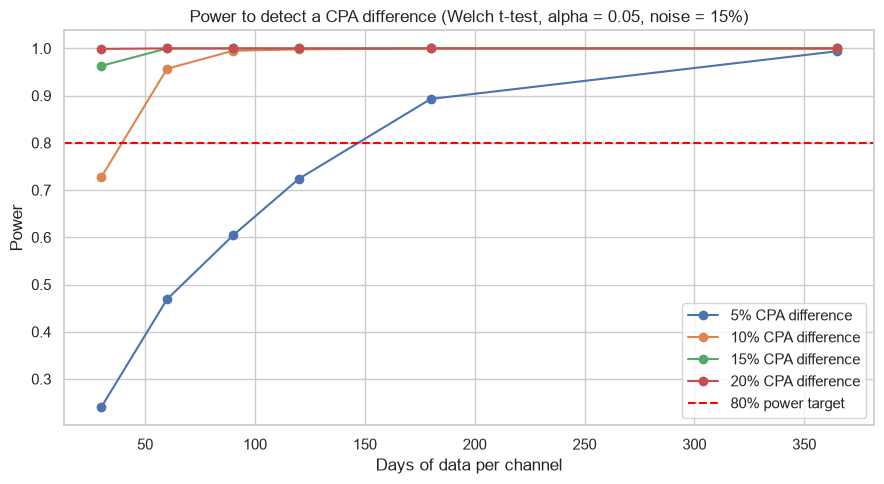

n_days,30,60,90,120,180,365
effect_size_pct,,,,,,
5,0.24,0.47,0.6,0.72,0.89,0.99
10,0.73,0.96,1.0,1.00,1.00,1.00
15,0.96,1.00,1.0,1.00,1.00,1.00
20,1.00,1.00,1.0,1.00,1.00,1.00


In [15]:
def empirical_power_cpa(true_diff_pct, base_cpa, n_days, n_sim=1000, alpha=0.05):
    """Share of simulated experiments where the t-test detects a TRUE CPA difference."""
    std = base_cpa * 0.15
    a = rng.normal(base_cpa, std, size=(n_sim, n_days))
    b = rng.normal(base_cpa * (1 + true_diff_pct), std, size=(n_sim, n_days))
    a = np.maximum(a, 0.5 * base_cpa)          # cap low values at 50% of base
    b = np.maximum(b, 0.5 * base_cpa)
    _, p = stats.ttest_ind(a, b, axis=1, equal_var=False)
    return (p < alpha).mean()

BASE_CPA = paid["CPA"].median()               # median daily CPA of the paid channels
print(f"Base CPA: ${BASE_CPA:.2f}")
effects = [0.05, 0.10, 0.15, 0.20]
days = [30, 60, 90, 120, 180, 365]            # 365 = what we actually have

power_df = pd.DataFrame([
    {"effect_size_pct": int(e * 100), "n_days": n, "power": empirical_power_cpa(e, BASE_CPA, n)}
    for e in effects for n in days
])

# Power curves
plt.figure(figsize=(9, 5))
for e, grp in power_df.groupby("effect_size_pct"):
    plt.plot(grp.n_days, grp.power, marker="o", label=f"{e}% CPA difference")
plt.axhline(0.8, color="red", linestyle="--", label="80% power target")
plt.xlabel("Days of data per channel")
plt.ylabel("Power")
plt.title("Power to detect a CPA difference (Welch t-test, alpha = 0.05, noise = 15%)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(OUT / "power_analysis_cpa.png", dpi=120)
plt.show()

power_df.pivot(index="effect_size_pct", columns="n_days", values="power").round(2)

In [16]:
# TODO: minimum days for 80% power, per effect size. Is our data enough? ("sufficient" / "insufficient")
...

# TODO: for each CPA pair significant after BH: observed % difference (smaller mean = baseline),
#       power with your number of days, and days needed for 80% if power < 0.8
...

TARGET = 0.80
N_HAVE = 365

# 1) Minimum days for 80% power, per effect size (simulation, steps of 5 days)
rows = []
for e in effects:
    needed = next((n for n in range(5, 1001, 5) if empirical_power_cpa(e, BASE_CPA, n, n_sim=500) >= TARGET), None)
    rows.append({"effect_size_pct": int(e * 100), "min_days_for_80pct": needed,
                 "our_data": f"{N_HAVE} days",
                 "status": "sufficient" if needed and needed <= N_HAVE else "insufficient"})
min_days_df = pd.DataFrame(rows)
display(min_days_df)

# 2) Our OBSERVED CPA gaps: no pair was significant after BH, so we check the biggest observed gaps instead.
#    Days needed for 80% power (normal approximation): n = 2 * ((z_a + z_b) * CV / diff)^2
z_a, z_b = stats.norm.ppf(1 - ALPHA / 2), stats.norm.ppf(TARGET)
real_cv = variability["CV"].mean()            # our actual day-to-day noise (~8.6%)

obs = cpa_res.copy()
obs["obs_diff_pct"] = (obs["diff"].abs() / obs[["mean_a", "mean_b"]].min(axis=1)) * 100   # smaller mean = baseline
obs = obs.sort_values("obs_diff_pct", ascending=False).head(3)
for _, r in obs.iterrows():
    d = r.obs_diff_pct / 100
    power_now = empirical_power_cpa(d, BASE_CPA, N_HAVE, n_sim=500)
    days_15 = 2 * ((z_a + z_b) * 0.15 / d) ** 2
    days_real = 2 * ((z_a + z_b) * real_cv / d) ** 2
    print(f"{r.group_a} vs {r.group_b}: observed gap {r.obs_diff_pct:.2f}% | power with {N_HAVE} days: {power_now:.0%} | "
          f"days for 80% power: ~{days_15:,.0f} (15% noise) / ~{days_real:,.0f} (our real {real_cv:.1%} noise)")

,effect_size_pct,min_days_for_80pct,our_data,status
0,5,150,365 days,sufficient
1,10,40,365 days,sufficient
2,15,20,365 days,sufficient
3,20,15,365 days,sufficient


Instagram vs Website: observed gap 1.17% | power with 365 days: 18% | days for 80% power: ~2,592 (15% noise) / ~853 (our real 8.6% noise)
Google Ads vs Website: observed gap 1.12% | power with 365 days: 16% | days for 80% power: ~2,802 (15% noise) / ~922 (our real 8.6% noise)
Website vs YouTube: observed gap 1.00% | power with 365 days: 14% | days for 80% power: ~3,557 (15% noise) / ~1,171 (our real 8.6% noise)


**✍️ Answer:**
1. **What size of CPA difference can your data detect reliably?** With **365 days per channel**, we have about **99 % power to detect a 5 % CPA difference** and practically 100 % for 10 % or more (simulation with 15 % day-to-day noise; our real noise is lower, about 8.6 %, so this is conservative). Reliable detection (≥ 80 % power) needs only **150 days for a 5 % gap**, 40 days for 10 %, 20 days for 15 % and 15 days for 20 %.
2. **How many days would you need to detect a 5 % difference?** About **150 days per channel** for 80 % power. **We have 365, so that is sufficient.**
3. **Non-significant pairs: "no difference" or "not enough data"?** **Both, depending on the size.** For any **meaningful** gap (5 % or more), the answer is **"no difference"**: we had about 99 % power and found nothing, so a gap that large very likely does not exist. For the **tiny gaps we actually observed** (1.0–1.2 %, e.g. Instagram vs Website), the answer is **"not enough data"**: power is only **14–18 %**, and proving them would take about **850–2,600 days** (2.5–7 years). Since gaps that small are not worth acting on anyway, **collecting more data to prove them is not worthwhile.**

💡 **Remember:** half the difference → about **4× the data**.

## Part 5 — Business recommendations (30–45 min)
### Step 8: From statistics to a decision

In [19]:
# TODO: summary of significant findings (use the BH-corrected results)
#  - CPA: which channel is cheaper, by how much ($), adjusted p-value, Cohen's d
#  - Conversion rate: which channel is higher, by how many points, adjusted p-value
...

print("=== CPA (Welch t-test, BH-corrected) ===")
sig_cpa = cpa_res[cpa_res.significant_fdr]
if sig_cpa.empty:
    print("No significant CPA differences after correction (0 of 15 pairs).")
else:
    for _, r in sig_cpa.iterrows():
        cheaper = r.group_a if r.mean_a < r.mean_b else r.group_b
        print(f"{cheaper} is cheaper: ${abs(r['diff']):.2f} gap, adj. p = {r.p_value_fdr:.4f}, Cohen's d = {r.cohens_d:.2f}")

print("\n=== Conversion rate (Fisher's exact test, BH-corrected) ===")
sig_cvr = fisher_res[fisher_res.significant_fdr].sort_values("p_value_fdr")
for _, r in sig_cvr.iterrows():
    higher, lower = (r.group_a, r.group_b) if r.rate_a > r.rate_b else (r.group_b, r.group_a)
    print(f"{higher} > {lower}: {abs(r.diff_pp):.3f} percentage points higher, adj. p = {r.p_value_fdr:.2e}")
print(f"\n{len(sig_cvr)} of 15 conversion-rate pairs significant after BH, but all gaps are below 0.06 percentage points.")

=== CPA (Welch t-test, BH-corrected) ===
No significant CPA differences after correction (0 of 15 pairs).

=== Conversion rate (Fisher's exact test, BH-corrected) ===
Email > YouTube: 0.056 percentage points higher, adj. p = 6.39e-09
Website > YouTube: 0.048 percentage points higher, adj. p = 5.17e-07
Email > Instagram: 0.045 percentage points higher, adj. p = 2.44e-06
Facebook > YouTube: 0.042 percentage points higher, adj. p = 1.02e-05
Website > Instagram: 0.037 percentage points higher, adj. p = 8.68e-05
Google Ads > YouTube: 0.032 percentage points higher, adj. p = 9.54e-04
Facebook > Instagram: 0.031 percentage points higher, adj. p = 1.05e-03
Email > Google Ads: 0.024 percentage points higher, adj. p = 1.36e-02
Google Ads > Instagram: 0.021 percentage points higher, adj. p = 3.19e-02

9 of 15 conversion-rate pairs significant after BH, but all gaps are below 0.06 percentage points.


In [20]:
def bootstrap_ci(data, n_bootstrap=1000, ci_level=0.95):
    """Bootstrap CI of the mean: resample with replacement, take the mean each time, return the percentiles."""
    data = np.asarray(data)
    means = rng.choice(data, size=(n_bootstrap, len(data)), replace=True).mean(axis=1)
    alpha = 1 - ci_level
    return np.percentile(means, 100 * alpha / 2), np.percentile(means, 100 * (1 - alpha / 2))

ci_rows = []
for ch in sorted(paid.channel.unique()):
    values = paid.loc[paid.channel == ch, "CPA"].dropna()
    low, high = bootstrap_ci(values)
    ci_rows.append({"channel": ch, "mean_daily_CPA": values.mean(), "ci_95_low": low, "ci_95_high": high,
                    "ci_width": high - low})
ci_df = pd.DataFrame(ci_rows).sort_values("mean_daily_CPA")
ci_df.to_csv(OUT / "cpa_confidence_intervals.csv", index=False)
ci_df.round(2)

,channel,mean_daily_CPA,ci_95_low,ci_95_high,ci_width
4,Website,283.62,281.15,286.11,4.96
0,Email,285.07,282.66,287.73,5.07
1,Facebook,285.57,283.13,287.96,4.83
5,YouTube,286.44,284.01,289.03,5.03
2,Google Ads,286.80,284.35,289.04,4.69
3,Instagram,286.93,284.33,289.75,5.42


In [21]:
# Composite score: rank CPA (lowest = best = highest rank) and ROAS (highest = best = highest rank)
score = agg[["CPA", "ROAS"]].copy()
score["CPA_rank"] = score["CPA"].rank(ascending=False)    # lowest CPA -> highest rank
score["ROAS_rank"] = score["ROAS"].rank(ascending=True)   # highest ROAS -> highest rank
score["composite"] = 0.5 * score["CPA_rank"] + 0.5 * score["ROAS_rank"]
score = score.sort_values("composite", ascending=False)

# Split $500,000 in proportion to the composite score, with min 5% and max 35% per channel
BUDGET = 500_000
MIN_SHARE, MAX_SHARE = 0.05, 0.35
share = score["composite"] / score["composite"].sum()
for _ in range(20):                                   # repeat until all shares respect the limits
    share = share.clip(MIN_SHARE, MAX_SHARE)
    free = ~share.isin([MIN_SHARE, MAX_SHARE])
    share[free] += (1 - share.sum()) * share[free] / share[free].sum()
score["allocation_pct"] = share
score["allocation_usd"] = (share * BUDGET).round(-2)

# Honest benchmark: no CPA difference was significant, so compare with an equal split
score["equal_split_usd"] = BUDGET / len(score)

score.to_csv(OUT / "budget_allocation.csv")
score.round(3)

,CPA,ROAS,CPA_rank,ROAS_rank,composite,allocation_pct,allocation_usd,equal_split_usd
channel,,,,,,,,
Website,281.928,6.011,6.0,5.0,5.5,0.262,131000.0,83333.333
Facebook,283.886,6.027,4.0,6.0,5.0,0.238,119000.0,83333.333
Email,283.336,5.999,5.0,2.0,3.5,0.167,83300.0,83333.333
YouTube,284.753,6.001,3.0,3.0,3.0,0.143,71400.0,83333.333
Google Ads,285.223,6.008,1.0,4.0,2.5,0.119,59500.0,83333.333
Instagram,285.128,5.986,2.0,1.0,1.5,0.071,35700.0,83333.333


💡 **Before you write the memo, think:**
- Two channels whose CPA difference is **not significant** still get different ranks. Is that fair?
- The top channel may be **small**. Can it really absorb a big budget at the same CPA?
- Which "significant" differences are **too small to matter**?

In [22]:
# TODO: write the executive memo as Markdown and save it
memo = f"""# Executive memo — Marketing budget allocation

**To:** CMO · **From:** Barsha Mishra, Marketing Analyst · **Date:** 23 November 2026
**Dataset:** Kaggle "Marketing Campaign Performance Dataset" (manishabhatt22), 200,000 campaigns aggregated to 6 channels × 365 days
**Period:** 1 January – 31 December 2021

## Executive summary
We tested whether any of our 6 channels (Email, Facebook, Google Ads, Instagram, Website, YouTube) is genuinely cheaper or more effective, before moving any of the $500K monthly budget. **No channel has a statistically significant CPA advantage.** All channels cost about $282–$285 per acquisition and return about 6× ad spend. The data was large enough to detect any real CPA difference of 5% or more, so we can say with confidence that **no channel is meaningfully better on cost**. We recommend **keeping the budget roughly equal** and running a controlled experiment before any major shift.

## Key findings
- **Top performers (point estimates only):** Website has the lowest CPA (${agg.loc['Website','CPA']:.2f}) and Facebook the highest ROAS ({agg.loc['Facebook','ROAS']:.2f}). The gap between best and worst CPA is only about **1%**.
- **Statistically significant differences (after correction):**
  - **CPA:** 0 of 15 channel pairs differ (Welch t-test on daily CPA; BH and Bonferroni corrected). Every effect size is negligible (|Cohen's d| ≤ 0.13).
  - **Conversion rate:** 9 of 15 pairs differ with Fisher's exact test (7 with Bonferroni), because each channel has about 18 million clicks. But all rates are **7.98–8.03%**, so the biggest gap is **0.056 percentage points**: real, but **too small to matter**. The t-test on daily conversion rates finds 0 differences.
- **Data adequacy (power):** with 365 days per channel we have about **99% power to detect a 5% CPA difference** (150 days would suffice). The gaps we observed (1.0–1.2%) would need about **850–2,600 days** (2.5–7 years) to prove, and are too small to justify that effort.

## Recommendations
1. **Do not reallocate budget based on these results.** A formula that ranks channels by CPA and ROAS would give Website $131K and Instagram $36K, a **3.7× difference built on noise**. Keep about **$83K per channel** (equal split) for now.
2. **If a small tilt is wanted**, move at most **5–10%** of budget towards Website and Facebook as a **test**, not a decision, and measure the result.
3. **Run a controlled experiment** (e.g. a geo or holdout test) to measure **incremental** conversions per channel. That answers what the historical data cannot: which channel causes extra sales.
4. **Shift the focus from channel choice to other levers** (creative, targeting, landing pages, customer segments), where differences are more likely to be large.

## Statistical caveats
- **Dataset source and limits:** a public Kaggle dataset, very likely **synthetic**. Conversions (rate × clicks) and revenue (cost × (1 + ROI)) were **derived**, not observed. Results show the method, not our real market.
- **Multiple comparisons correction:** 45 tests were run (about 2.25 false positives expected by chance). We used **Benjamini-Hochberg** and, for budget decisions, the stricter **Bonferroni** correction.
- **Confidence intervals:** the 95% bootstrap CIs for daily CPA all overlap (about $281–$290), e.g. Website ${ci_df.set_index('channel').loc['Website','ci_95_low']:.2f}–${ci_df.set_index('channel').loc['Website','ci_95_high']:.2f}.
- **External factors:** seasonality, promotions, attribution rules and campaign mix (company, audience, location) were not controlled. Historical correlations are not causal effects.
- **Statistical vs practical significance:** with 18 million clicks per channel, tiny differences become "significant". We judge the **size** of a difference, not just its p-value.
- **Power limitations:** the simulation assumed normal daily CPA with 15% noise (our real noise is about 8.6%, so the estimates are conservative). It also assumes stable conditions over time.
- **Scalability:** a channel's CPA may rise if it receives much more budget (diminishing returns), which this data cannot show.

## Next steps
1. Keep the current, roughly equal allocation for the next month.
2. Design a 6–8 week **geo or holdout experiment** for the 2–3 largest channels, with a pre-defined success metric (incremental CPA) and a sample size based on this power analysis.
3. Repeat this analysis on **our own first-party data**, with real conversions and revenue, before any major reallocation.
4. Review creative and audience performance within channels, where larger gains are more likely.
"""
(OUT / "executive_memo.md").write_text(memo, encoding="utf-8")
display(Markdown(memo))

# Executive memo — Marketing budget allocation

**To:** CMO · **From:** Barsha Mishra, Marketing Analyst · **Date:** 23 November 2026
**Dataset:** Kaggle "Marketing Campaign Performance Dataset" (manishabhatt22), 200,000 campaigns aggregated to 6 channels × 365 days
**Period:** 1 January – 31 December 2021

## Executive summary
We tested whether any of our 6 channels (Email, Facebook, Google Ads, Instagram, Website, YouTube) is genuinely cheaper or more effective, before moving any of the $500K monthly budget. **No channel has a statistically significant CPA advantage.** All channels cost about $282–$285 per acquisition and return about 6× ad spend. The data was large enough to detect any real CPA difference of 5% or more, so we can say with confidence that **no channel is meaningfully better on cost**. We recommend **keeping the budget roughly equal** and running a controlled experiment before any major shift.

## Key findings
- **Top performers (point estimates only):** Website has the lowest CPA ($281.93) and Facebook the highest ROAS (6.03). The gap between best and worst CPA is only about **1%**.
- **Statistically significant differences (after correction):**
  - **CPA:** 0 of 15 channel pairs differ (Welch t-test on daily CPA; BH and Bonferroni corrected). Every effect size is negligible (|Cohen's d| ≤ 0.13).
  - **Conversion rate:** 9 of 15 pairs differ with Fisher's exact test (7 with Bonferroni), because each channel has about 18 million clicks. But all rates are **7.98–8.03%**, so the biggest gap is **0.056 percentage points**: real, but **too small to matter**. The t-test on daily conversion rates finds 0 differences.
- **Data adequacy (power):** with 365 days per channel we have about **99% power to detect a 5% CPA difference** (150 days would suffice). The gaps we observed (1.0–1.2%) would need about **850–2,600 days** (2.5–7 years) to prove, and are too small to justify that effort.

## Recommendations
1. **Do not reallocate budget based on these results.** A formula that ranks channels by CPA and ROAS would give Website $131K and Instagram $36K, a **3.7× difference built on noise**. Keep about **$83K per channel** (equal split) for now.
2. **If a small tilt is wanted**, move at most **5–10%** of budget towards Website and Facebook as a **test**, not a decision, and measure the result.
3. **Run a controlled experiment** (e.g. a geo or holdout test) to measure **incremental** conversions per channel. That answers what the historical data cannot: which channel causes extra sales.
4. **Shift the focus from channel choice to other levers** (creative, targeting, landing pages, customer segments), where differences are more likely to be large.

## Statistical caveats
- **Dataset source and limits:** a public Kaggle dataset, very likely **synthetic**. Conversions (rate × clicks) and revenue (cost × (1 + ROI)) were **derived**, not observed. Results show the method, not our real market.
- **Multiple comparisons correction:** 45 tests were run (about 2.25 false positives expected by chance). We used **Benjamini-Hochberg** and, for budget decisions, the stricter **Bonferroni** correction.
- **Confidence intervals:** the 95% bootstrap CIs for daily CPA all overlap (about $281–$290), e.g. Website $281.15–$286.11.
- **External factors:** seasonality, promotions, attribution rules and campaign mix (company, audience, location) were not controlled. Historical correlations are not causal effects.
- **Statistical vs practical significance:** with 18 million clicks per channel, tiny differences become "significant". We judge the **size** of a difference, not just its p-value.
- **Power limitations:** the simulation assumed normal daily CPA with 15% noise (our real noise is about 8.6%, so the estimates are conservative). It also assumes stable conditions over time.
- **Scalability:** a channel's CPA may rise if it receives much more budget (diminishing returns), which this data cannot show.

## Next steps
1. Keep the current, roughly equal allocation for the next month.
2. Design a 6–8 week **geo or holdout experiment** for the 2–3 largest channels, with a pre-defined success metric (incremental CPA) and a sample size based on this power analysis.
3. Repeat this analysis on **our own first-party data**, with real conversions and revenue, before any major reallocation.
4. Review creative and audience performance within channels, where larger gains are more likely.


## Reflection (optional, recommended): `reflection.md`
1. What surprised you about the results?
2. How did multiple-comparison correction change your conclusions?
3. What are the limits of this analysis?
4. How would you explain the findings to a non-technical CMO in one minute?

## Submission checklist
- [ ] GitHub repo with only this lab, plus a `README.md` (how to run + file map)
- [ ] `lab_proof.md` as the entry point (code/workflow, one run with its input, the evidence, the final output, one failure or limitation you hit)
- [ ] Notebook(s) run top to bottom without errors
- [ ] `outputs/`: `marketing_data.csv`, the 5 charts, `executive_memo.md`